In [118]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import arff

print("All libraries imported successfully!")

All libraries imported successfully!


In [119]:
# Load the .arff file
data, meta = arff.loadarff('../data/raw/Training Dataset.arff')

# Convert to pandas DataFrame
df = pd.DataFrame(data)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (11055, 31)


In [120]:
# Show first 5 rows
print("First 5 rows:")
df.head()

First 5 rows:


,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,b'-1',b'1',b'1',b'1',b'-1',b'-1',b'-1',b'-1',b'-1',b'1',...,b'1',b'1',b'-1',b'-1',b'-1',b'-1',b'1',b'1',b'-1',b'-1'
1,b'1',b'1',b'1',b'1',b'1',b'-1',b'0',b'1',b'-1',b'1',...,b'1',b'1',b'-1',b'-1',b'0',b'-1',b'1',b'1',b'1',b'-1'
2,b'1',b'0',b'1',b'1',b'1',b'-1',b'-1',b'-1',b'-1',b'1',...,b'1',b'1',b'1',b'-1',b'1',b'-1',b'1',b'0',b'-1',b'-1'
3,b'1',b'0',b'1',b'1',b'1',b'-1',b'-1',b'-1',b'1',b'1',...,b'1',b'1',b'-1',b'-1',b'1',b'-1',b'1',b'-1',b'1',b'-1'
4,b'1',b'0',b'-1',b'1',b'1',b'-1',b'1',b'1',b'-1',b'1',...,b'-1',b'1',b'-1',b'-1',b'0',b'-1',b'1',b'1',b'1',b'1'


In [124]:
# Show all column names
print("Column names:")
print(df.columns.tolist())

Column names:
['having_IP_Address', 'URL_Length', 'Shortining_Service', 'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length', 'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor', 'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL', 'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe', 'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank', 'Google_Index', 'Links_pointing_to_page', 'Statistical_report', 'Result']


In [125]:
# Check data types and missing values
print("Dataset Info:")
print(df.info())

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11055 entries, 0 to 11054
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   having_IP_Address            11055 non-null  object
 1   URL_Length                   11055 non-null  object
 2   Shortining_Service           11055 non-null  object
 3   having_At_Symbol             11055 non-null  object
 4   double_slash_redirecting     11055 non-null  object
 5   Prefix_Suffix                11055 non-null  object
 6   having_Sub_Domain            11055 non-null  object
 7   SSLfinal_State               11055 non-null  object
 8   Domain_registeration_length  11055 non-null  object
 9   Favicon                      11055 non-null  object
 10  port                         11055 non-null  object
 11  HTTPS_token                  11055 non-null  object
 12  Request_URL                  11055 non-null  object
 13  URL_of_Anchor    

In [126]:
# Convert byte strings to integers
df = df.map(lambda x: int(x.decode('utf-8')))

print("Data types after conversion:")
print(df.dtypes.value_counts())
print("\nFirst 5 rows after conversion:")
df.head()

Data types after conversion:
int64    31
Name: count, dtype: int64

First 5 rows after conversion:


,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


In [127]:
# Check how many phishing vs legitimate URLs we have
print("Target column distribution:")
print(df['Result'].value_counts())
print("\nPercentage:")
print(df['Result'].value_counts(normalize=True) * 100)

Target column distribution:
Result
 1    6157
-1    4898
Name: count, dtype: int64

Percentage:
Result
 1    55.694256
-1    44.305744
Name: proportion, dtype: float64


In [128]:
# Check for duplicates
print("Number of duplicate rows:", df.duplicated().sum())

# Remove duplicates if any
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Number of duplicate rows: 5206
Shape after removing duplicates: (5849, 31)


In [129]:
# Check missing values
print("Missing values per column:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())

Missing values per column:
having_IP_Address              0
URL_Length                     0
Shortining_Service             0
having_At_Symbol               0
double_slash_redirecting       0
Prefix_Suffix                  0
having_Sub_Domain              0
SSLfinal_State                 0
Domain_registeration_length    0
Favicon                        0
port                           0
HTTPS_token                    0
Request_URL                    0
URL_of_Anchor                  0
Links_in_tags                  0
SFH                            0
Submitting_to_email            0
Abnormal_URL                   0
Redirect                       0
on_mouseover                   0
RightClick                     0
popUpWidnow                    0
Iframe                         0
age_of_domain                  0
DNSRecord                      0
web_traffic                    0
Page_Rank                      0
Google_Index                   0
Links_pointing_to_page         0
Statistical_repo

In [130]:
# Check unique values in each column
print("Unique values in each column:")
for col in df.columns:
    unique_vals = df[col].unique()
    print(f"{col}: {sorted(unique_vals)}")

Unique values in each column:
having_IP_Address: [np.int64(-1), np.int64(1)]
URL_Length: [np.int64(-1), np.int64(0), np.int64(1)]
Shortining_Service: [np.int64(-1), np.int64(1)]
having_At_Symbol: [np.int64(-1), np.int64(1)]
double_slash_redirecting: [np.int64(-1), np.int64(1)]
Prefix_Suffix: [np.int64(-1), np.int64(1)]
having_Sub_Domain: [np.int64(-1), np.int64(0), np.int64(1)]
SSLfinal_State: [np.int64(-1), np.int64(0), np.int64(1)]
Domain_registeration_length: [np.int64(-1), np.int64(1)]
Favicon: [np.int64(-1), np.int64(1)]
port: [np.int64(-1), np.int64(1)]
HTTPS_token: [np.int64(-1), np.int64(1)]
Request_URL: [np.int64(-1), np.int64(1)]
URL_of_Anchor: [np.int64(-1), np.int64(0), np.int64(1)]
Links_in_tags: [np.int64(-1), np.int64(0), np.int64(1)]
SFH: [np.int64(-1), np.int64(0), np.int64(1)]
Submitting_to_email: [np.int64(-1), np.int64(1)]
Abnormal_URL: [np.int64(-1), np.int64(1)]
Redirect: [np.int64(0), np.int64(1)]
on_mouseover: [np.int64(-1), np.int64(1)]
RightClick: [np.int64(-1

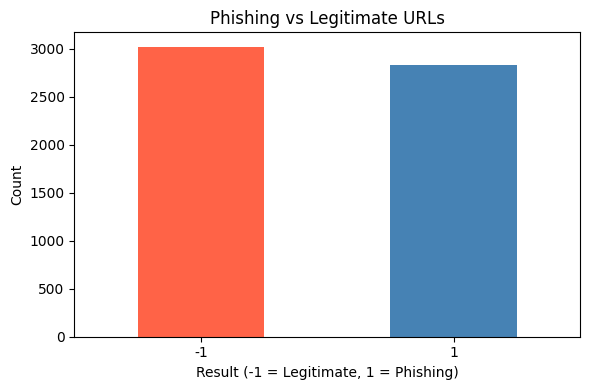

Cleaned dataset distribution:
Result
-1    3019
 1    2830
Name: count, dtype: int64


In [131]:
# Visualize phishing vs legitimate distribution
plt.figure(figsize=(6, 4))
df['Result'].value_counts().plot(kind='bar', color=['tomato', 'steelblue'])
plt.title('Phishing vs Legitimate URLs')
plt.xlabel('Result (-1 = Legitimate, 1 = Phishing)')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Cleaned dataset distribution:")
print(df['Result'].value_counts())

In [133]:
# Save cleaned dataset as CSV
df.to_csv('/Users/binitapandey/phishing-detection-ml-system/data/raw/phishing_urls_cleaned.csv', index=False)
print("Cleaned dataset saved successfully!")
print("Final shape:", df.shape)

Cleaned dataset saved successfully!
Final shape: (5849, 31)


In [134]:
# Test the updated script
import sys
sys.path.append('/Users/binitapandey/phishing-detection-ml-system')

from src.preprocessing.prepare_phishing_url import load_and_clean_phishing_url_dataset

df_final = load_and_clean_phishing_url_dataset(
    '/Users/binitapandey/phishing-detection-ml-system/data/raw/Training Dataset.arff',
    '/Users/binitapandey/phishing-detection-ml-system/data/processed/phishing_urls_cleaned.csv'
)

Step 1: Loading dataset...
Original shape: (11055, 31)

Step 2: Decoding byte strings using pandas...
Decoding complete.
Data types:
int64    31
Name: count, dtype: int64

Step 3: Auditing missing values...
Total missing values found: 0
No missing values found. Dataset is clean.

Step 4: Removing duplicates...
Removed 5206 duplicate rows.
Shape after removing duplicates: (5849, 31)

Step 5: Separating features and target...
Features shape: (5849, 30)
Target shape: (5849,)

Step 6: Checking class imbalance...
Class distribution:
Result
-1    3019
 1    2830
Name: count, dtype: int64
Minority/Majority ratio: 0.94
Classes are balanced. SMOTE not needed.

Step 7: Applying MinMaxScaler...
Scaling complete. All features now in range [0, 1].
Sample scaled values:
   having_IP_Address  URL_Length  Shortining_Service  having_At_Symbol  \
0                0.0         1.0                 1.0               1.0   
1                1.0         1.0                 1.0               1.0   
2          

In [135]:
df=pd.read_csv("/Users/binitapandey/phishing-detection-ml-system/data/processed/phishing_urls_cleaned.csv")

In [136]:
df.head()

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,-1
1,1.0,1.0,1.0,1.0,1.0,0.0,0.5,1.0,0.0,1.0,...,1.0,1.0,0.0,0.0,0.5,0.0,1.0,1.0,1.0,-1
2,1.0,0.5,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,1.0,0.0,1.0,0.0,1.0,0.5,0.0,-1
3,1.0,0.5,1.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,...,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,-1
4,1.0,0.5,0.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.5,0.0,1.0,1.0,1.0,1


In [137]:
X=df.drop('Result', axis=1)
Y=df['Result']

In [138]:
df.head()

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,-1
1,1.0,1.0,1.0,1.0,1.0,0.0,0.5,1.0,0.0,1.0,...,1.0,1.0,0.0,0.0,0.5,0.0,1.0,1.0,1.0,-1
2,1.0,0.5,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,1.0,0.0,1.0,0.0,1.0,0.5,0.0,-1
3,1.0,0.5,1.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,...,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,-1
4,1.0,0.5,0.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.5,0.0,1.0,1.0,1.0,1


In [139]:
df.tail()

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
5844,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,1.0,0.0,0.5,0.0,1.0,0.5,1.0,-1
5845,1.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,...,1.0,1.0,1.0,1.0,0.5,0.0,1.0,0.5,1.0,1
5846,1.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,0.5,0.0,1.0,0.5,1.0,1
5847,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,...,1.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,-1
5848,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,...,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,-1


In [140]:
df.sample()

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
671,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1


In [141]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5849 entries, 0 to 5848
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   having_IP_Address            5849 non-null   float64
 1   URL_Length                   5849 non-null   float64
 2   Shortining_Service           5849 non-null   float64
 3   having_At_Symbol             5849 non-null   float64
 4   double_slash_redirecting     5849 non-null   float64
 5   Prefix_Suffix                5849 non-null   float64
 6   having_Sub_Domain            5849 non-null   float64
 7   SSLfinal_State               5849 non-null   float64
 8   Domain_registeration_length  5849 non-null   float64
 9   Favicon                      5849 non-null   float64
 10  port                         5849 non-null   float64
 11  HTTPS_token                  5849 non-null   float64
 12  Request_URL                  5849 non-null   float64
 13  URL_of_Anchor     

In [143]:
X.head()

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,RightClick,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report
0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1,1.0,1.0,1.0,1.0,1.0,0.0,0.5,1.0,0.0,1.0,...,1.0,1.0,1.0,0.0,0.0,0.5,0.0,1.0,1.0,1.0
2,1.0,0.5,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,0.5,0.0
3,1.0,0.5,1.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,...,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
4,1.0,0.5,0.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.5,0.0,1.0,1.0,1.0


In [144]:
Y.head(2789)

0      -1
1      -1
2      -1
3      -1
4       1
       ..
2784    1
2785    1
2786   -1
2787   -1
2788    1
Name: Result, Length: 2789, dtype: int64

In [145]:
pip install scikit-learn

You should consider upgrading via the '/Users/binitapandey/phishing-detection-ml-system/venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [146]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

In [147]:
df.shape

(5849, 31)

In [148]:
print("Training set shape:",X_train.shape)
print("Testing set shape:",X_test.shape)
print("Train distribution:")
print(y_train.value_counts())

print("\nTest distribution:")
print(y_test.value_counts())


Training set shape: (4679, 30)
Testing set shape: (1170, 30)
Train distribution:
Result
-1    2415
 1    2264
Name: count, dtype: int64

Test distribution:
Result
-1    604
 1    566
Name: count, dtype: int64


In [149]:
from sklearn.linear_model import LogisticRegression

In [150]:
model = LogisticRegression(max_iter=1000)

In [151]:
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [153]:
y_pred = model.predict(X_test)

In [154]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(results.head(20))

    Actual  Predicted
0       -1         -1
1       -1         -1
2       -1         -1
3       -1         -1
4        1         -1
5        1          1
6       -1         -1
7        1          1
8       -1          1
9       -1         -1
10      -1         -1
11       1          1
12      -1         -1
13       1          1
14      -1         -1
15       1         -1
16       1          1
17       1         -1
18       1          1
19       1          1


In [155]:
results.value_counts()

Actual  Predicted
-1      -1           546
 1       1           522
-1       1            58
 1      -1            44
Name: count, dtype: int64

In [156]:
from sklearn.metrics import accuracy_score

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9128205128205128


In [157]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          -1       0.93      0.90      0.91       604
           1       0.90      0.92      0.91       566

    accuracy                           0.91      1170
   macro avg       0.91      0.91      0.91      1170
weighted avg       0.91      0.91      0.91      1170



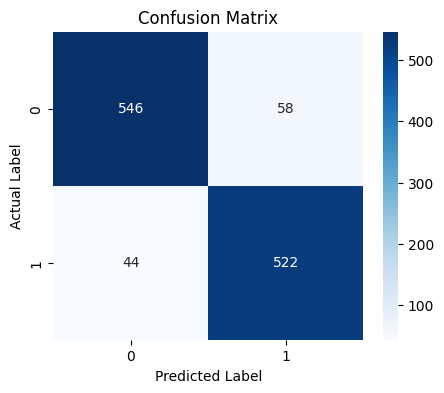

In [158]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")

plt.show()

In [159]:
X.columns

Index(['having_IP_Address', 'URL_Length', 'Shortining_Service',
       'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix',
       'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length',
       'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor',
       'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL',
       'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe',
       'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank',
       'Google_Index', 'Links_pointing_to_page', 'Statistical_report'],
      dtype='object')

In [160]:
X.head()

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,RightClick,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report
0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1,1.0,1.0,1.0,1.0,1.0,0.0,0.5,1.0,0.0,1.0,...,1.0,1.0,1.0,0.0,0.0,0.5,0.0,1.0,1.0,1.0
2,1.0,0.5,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,0.5,0.0
3,1.0,0.5,1.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,...,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
4,1.0,0.5,0.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.5,0.0,1.0,1.0,1.0


In [161]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(random_state=42)


In [162]:
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [163]:
y_pred_rf = rf_model.predict(X_test)

In [42]:
type(y_pred_rf)

numpy.ndarray

In [164]:
type(df)

pandas.core.frame.DataFrame

In [165]:
result_ran= pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_rf
})

print(result_ran.head(20))

    Actual  Predicted
0       -1         -1
1       -1         -1
2       -1         -1
3       -1         -1
4        1          1
5        1          1
6       -1         -1
7        1          1
8       -1          1
9       -1         -1
10      -1         -1
11       1          1
12      -1         -1
13       1          1
14      -1         -1
15       1          1
16       1          1
17       1         -1
18       1          1
19       1          1


In [166]:
print(result_ran.head(20))

    Actual  Predicted
0       -1         -1
1       -1         -1
2       -1         -1
3       -1         -1
4        1          1
5        1          1
6       -1         -1
7        1          1
8       -1          1
9       -1         -1
10      -1         -1
11       1          1
12      -1         -1
13       1          1
14      -1         -1
15       1          1
16       1          1
17       1         -1
18       1          1
19       1          1


In [168]:
from sklearn.metrics import accuracy_score
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))

Random Forest Accuracy: 0.9435897435897436


In [169]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y_test, y_pred_rf)
recall = recall_score(y_test, y_pred_rf)
f1 = f1_score(y_test, y_pred_rf)

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Precision: 0.9385964912280702
Recall: 0.9452296819787986
F1 Score: 0.9419014084507042


In [170]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

          -1       0.95      0.94      0.95       604
           1       0.94      0.95      0.94       566

    accuracy                           0.94      1170
   macro avg       0.94      0.94      0.94      1170
weighted avg       0.94      0.94      0.94      1170



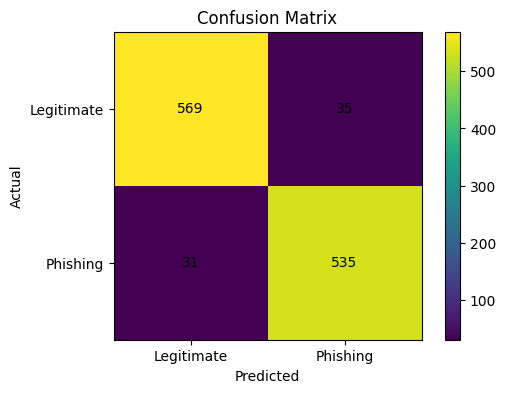

In [171]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 4))
plt.imshow(cm)
plt.colorbar()

plt.xticks([0, 1], ['Legitimate', 'Phishing'])
plt.yticks([0, 1], ['Legitimate', 'Phishing'])

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')

for i in range(len(cm)):
    for j in range(len(cm[0])):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.show()

In [172]:
cm = confusion_matrix(y_test, y_pred_rf)

print(cm.sum())
print(len(y_test))

1170
1170


In [174]:
from xgboost import XGBClassifier

In [175]:
Y.value_counts()

Result
-1    3019
 1    2830
Name: count, dtype: int64

In [176]:
Y=Y.replace({-1:0,1:1})

In [177]:
Y.value_counts()

Result
0    3019
1    2830
Name: count, dtype: int64

In [178]:
X_train_xgb=X_train.replace({-1:0,1:1})
X_test_xgb=X_test.replace({-1:0,1:1})
y_train_xgb=y_train.replace({-1:0,1:1})
y_test_xgb=y_test.replace({-1:0,1:1})

In [179]:
xgb_model = XGBClassifier(
    random_state=42,
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6
)

xgb_model.fit(X_train_xgb, y_train_xgb)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, random_state=42, ...)

In [180]:
y_predict_xgb=xgb_model.predict(X_test_xgb)

In [181]:
accuracy=accuracy_score(y_test_xgb, y_predict_xgb)
print(accuracy)
print(classification_report(y_test_xgb, y_predict_xgb))

0.9512820512820512
              precision    recall  f1-score   support

           0       0.95      0.95      0.95       604
           1       0.95      0.95      0.95       566

    accuracy                           0.95      1170
   macro avg       0.95      0.95      0.95      1170
weighted avg       0.95      0.95      0.95      1170



In [182]:
cm=confusion_matrix(y_test_xgb, y_predict_xgb)
print(cm)

[[576  28]
 [ 29 537]]


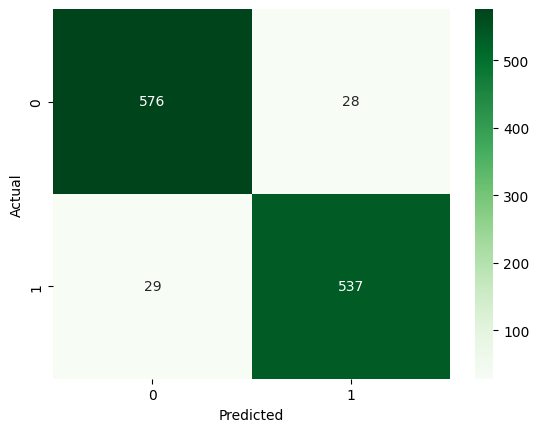

In [183]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [184]:
results = X_test.copy()

results['Actual'] = y_test_xgb
results['Predicted'] = y_predict_xgb
results.head(117)

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Actual,Predicted
5263,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,...,1.0,1.0,1.0,1.0,0.0,0.0,0.5,1.0,0,0
4468,1.0,0.0,1.0,1.0,1.0,0.0,0.5,0.0,1.0,1.0,...,1.0,1.0,1.0,1.0,0.0,1.0,0.5,1.0,0,0
4543,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,...,1.0,1.0,1.0,0.5,0.0,1.0,0.5,1.0,0,0
4810,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0,0
973,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,1.0,0.5,1.0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5468,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,0.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1,1
1357,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.5,1.0,0,0
5377,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,...,1.0,0.0,1.0,0.0,0.0,1.0,0.5,1.0,1,1
5814,1.0,0.0,1.0,1.0,1.0,0.0,0.5,0.5,0.0,1.0,...,1.0,1.0,1.0,1.0,0.0,1.0,0.5,1.0,0,0


In [185]:
mistakes= results[
    results['Actual'] != results['Predicted']]
mistakes.head()

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Actual,Predicted
2796,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,...,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,0,1
833,1.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,...,1.0,1.0,0.0,1.0,0.0,1.0,0.5,1.0,1,0
2655,1.0,0.0,1.0,1.0,1.0,0.0,0.5,0.0,1.0,1.0,...,1.0,0.0,1.0,1.0,0.0,1.0,0.5,1.0,1,0
1182,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.5,0.0,0.0,1.0,1.0,1,0
1736,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,...,1.0,1.0,0.0,0.5,0.0,1.0,0.5,1.0,0,1


In [186]:
mistakes

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Actual,Predicted
2796,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,...,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,0,1
833,1.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,...,1.0,1.0,0.0,1.0,0.0,1.0,0.5,1.0,1,0
2655,1.0,0.0,1.0,1.0,1.0,0.0,0.5,0.0,1.0,1.0,...,1.0,0.0,1.0,1.0,0.0,1.0,0.5,1.0,1,0
1182,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.5,0.0,0.0,1.0,1.0,1,0
1736,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,...,1.0,1.0,0.0,0.5,0.0,1.0,0.5,1.0,0,1
1770,1.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,...,1.0,1.0,1.0,0.5,0.0,1.0,0.5,0.0,1,0
5653,1.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,...,1.0,1.0,1.0,0.5,0.0,1.0,0.5,1.0,1,0
3806,0.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,...,1.0,0.0,1.0,0.5,1.0,1.0,0.5,1.0,0,1
5346,0.0,1.0,0.0,1.0,0.0,0.0,0.5,1.0,0.0,1.0,...,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,0,1
3048,1.0,0.0,1.0,1.0,1.0,0.0,0.5,1.0,1.0,1.0,...,1.0,0.0,1.0,0.5,1.0,1.0,1.0,1.0,1,0


In [187]:
type(X_test)

pandas.core.frame.DataFrame

In [188]:
results.head()

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Actual,Predicted
5263,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,...,1.0,1.0,1.0,1.0,0.0,0.0,0.5,1.0,0,0
4468,1.0,0.0,1.0,1.0,1.0,0.0,0.5,0.0,1.0,1.0,...,1.0,1.0,1.0,1.0,0.0,1.0,0.5,1.0,0,0
4543,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,...,1.0,1.0,1.0,0.5,0.0,1.0,0.5,1.0,0,0
4810,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0,0
973,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,1.0,0.5,1.0,1,1


In [189]:
print(y_train_xgb.value_counts())

Result
0    2415
1    2264
Name: count, dtype: int64


In [190]:
df['Result'].value_counts()

Result
-1    3019
 1    2830
Name: count, dtype: int64

In [191]:
false_positive = results[
    (results['Actual'] == 0) &
    (results['Predicted'] == 1)
]

false_negative = results[
    (results['Actual'] == 1) &
    (results['Predicted'] == 0)
]

print("False Positives:", len(false_positive))
print("False Negatives:", len(false_negative))

False Positives: 28
False Negatives: 29


In [192]:
false_positive.head(28)

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Actual,Predicted
2796,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,...,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,0,1
1736,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,...,1.0,1.0,0.0,0.5,0.0,1.0,0.5,1.0,0,1
3806,0.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,...,1.0,0.0,1.0,0.5,1.0,1.0,0.5,1.0,0,1
5346,0.0,1.0,0.0,1.0,0.0,0.0,0.5,1.0,0.0,1.0,...,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,0,1
1740,1.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,1.0,1.0,0.0,0.0,0.0,1.0,0.5,1.0,0,1
5114,0.0,0.0,1.0,1.0,1.0,0.0,0.5,0.0,0.0,0.0,...,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0,1
2836,1.0,0.0,1.0,1.0,1.0,0.0,0.5,1.0,0.0,1.0,...,1.0,0.0,1.0,1.0,0.0,1.0,0.5,1.0,0,1
96,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,...,1.0,1.0,0.0,0.5,0.0,1.0,0.0,1.0,0,1
5298,0.0,0.0,1.0,1.0,1.0,0.0,0.5,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,0,1
16,1.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,...,1.0,1.0,0.0,0.5,0.0,1.0,1.0,0.0,0,1


In [193]:
false_negative.head(29)

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Actual,Predicted
833,1.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,...,1.0,1.0,0.0,1.0,0.0,1.0,0.5,1.0,1,0
2655,1.0,0.0,1.0,1.0,1.0,0.0,0.5,0.0,1.0,1.0,...,1.0,0.0,1.0,1.0,0.0,1.0,0.5,1.0,1,0
1182,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.5,0.0,0.0,1.0,1.0,1,0
1770,1.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,...,1.0,1.0,1.0,0.5,0.0,1.0,0.5,0.0,1,0
5653,1.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,...,1.0,1.0,1.0,0.5,0.0,1.0,0.5,1.0,1,0
3048,1.0,0.0,1.0,1.0,1.0,0.0,0.5,1.0,1.0,1.0,...,1.0,0.0,1.0,0.5,1.0,1.0,1.0,1.0,1,0
2269,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,...,1.0,0.0,1.0,0.5,0.0,1.0,0.5,1.0,1,0
2918,0.0,0.0,1.0,1.0,1.0,0.0,0.5,0.0,1.0,1.0,...,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,1,0
346,1.0,0.0,1.0,1.0,1.0,0.0,0.5,1.0,0.0,1.0,...,1.0,0.0,1.0,0.5,0.0,0.0,0.5,1.0,1,0
1882,0.0,0.0,1.0,0.0,1.0,0.0,0.5,0.0,0.0,1.0,...,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1,0


In [194]:
comparison = pd.DataFrame({
    'False_Negative': false_negative.mean(numeric_only=True),
    'All_Test': X_test.mean(numeric_only=True)
})

comparison

,False_Negative,All_Test
Abnormal_URL,0.965517,0.843590
Actual,1.000000,NaN
DNSRecord,0.793103,0.762393
Domain_registeration_length,0.620690,0.355556
Favicon,0.965517,0.795726
Google_Index,0.862069,0.836752
HTTPS_token,0.931034,0.829915
Iframe,1.000000,0.900000
Links_in_tags,0.172414,0.428205
Links_pointing_to_page,0.724138,0.663248


In [195]:
comparison = pd.DataFrame({
    'False_Negative': false_negative.drop(
        columns=['Actual','Predicted']
    ).mean(numeric_only=True),

    'All_Test': X_test.mean(numeric_only=True)
})
comparison

,False_Negative,All_Test
having_IP_Address,0.689655,0.556410
URL_Length,0.103448,0.206410
Shortining_Service,0.965517,0.875214
having_At_Symbol,0.931034,0.788034
double_slash_redirecting,0.965517,0.876923
Prefix_Suffix,0.000000,0.119658
having_Sub_Domain,0.568966,0.538462
SSLfinal_State,0.431034,0.569658
Domain_registeration_length,0.620690,0.355556
Favicon,0.965517,0.795726


In [196]:
true_positive = results[
    (results['Actual'] == 1) &
    (results['Predicted'] == 1)
]

In [197]:
comparison = pd.DataFrame({
    'True_Positive': true_positive.drop(columns=['Actual','Predicted']).mean(numeric_only=True),
    'False_Negative': false_negative.drop(columns=['Actual','Predicted']).mean(numeric_only=True)
})

comparison

,True_Positive,False_Negative
having_IP_Address,0.601490,0.689655
URL_Length,0.254190,0.103448
Shortining_Service,0.836127,0.965517
having_At_Symbol,0.783985,0.931034
double_slash_redirecting,0.847300,0.965517
Prefix_Suffix,0.260708,0.000000
having_Sub_Domain,0.667598,0.568966
SSLfinal_State,0.913408,0.431034
Domain_registeration_length,0.227188,0.620690
Favicon,0.769088,0.965517


In [198]:
importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': xgb_model.feature_importances_
})

importance.sort_values(
    by='Importance',
    ascending=False
).head(30)

,Feature,Importance
7,SSLfinal_State,0.422709
13,URL_of_Anchor,0.159837
5,Prefix_Suffix,0.069134
15,SFH,0.033064
14,Links_in_tags,0.023977
2,Shortining_Service,0.018520
8,Domain_registeration_length,0.017604
27,Google_Index,0.017344
25,web_traffic,0.017191
9,Favicon,0.015480


In [199]:
false_negative['SSLfinal_State'].value_counts()


SSLfinal_State
0.0    16
1.0    12
0.5     1
Name: count, dtype: int64

In [200]:
results['SSLfinal_State'].value_counts()

SSLfinal_State
1.0    595
0.0    432
0.5    143
Name: count, dtype: int64

In [201]:
df['SSLfinal_State'].value_counts()

SSLfinal_State
1.0    3000
0.0    2128
0.5     721
Name: count, dtype: int64

In [202]:
X_train['SSLfinal_State'].unique()

array([0. , 0.5, 1. ])

In [203]:
truepositive_ssl=true_positive['SSLfinal_State'].value_counts(normalize=True)
falsepositive_ssl=false_negative['SSLfinal_State'].value_counts(normalize=True)
print(truepositive_ssl)
print(falsepositive_ssl)

SSLfinal_State
1.0    0.912477
0.0    0.085661
0.5    0.001862
Name: proportion, dtype: float64
SSLfinal_State
0.0    0.551724
1.0    0.413793
0.5    0.034483
Name: proportion, dtype: float64


In [204]:
Phising_probability=results['Phising_Probability'] = xgb_model.predict_proba(X_test)[:,1]
print(Phising_probability)

[1.07554225e-02 7.69987935e-04 7.99258763e-04 ... 2.62693405e-01
 4.97046597e-02 9.42914963e-01]


In [205]:
false_negative = results[
    (results['Actual'] == 1) &
    (results['Predicted'] == 0)
]
false_negative[['Phising_Probability']].sort_values(
    by='Phising_Probability' 
).head(10)

,Phising_Probability
333,0.121123
346,0.129901
4014,0.134654
4638,0.140956
2918,0.154809
1551,0.181326
250,0.181781
1912,0.214727
5733,0.241641
2655,0.246721


In [206]:
false_negative.head(10)

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Actual,Predicted,Phising_Probability
833,1.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,...,1.0,0.0,1.0,0.0,1.0,0.5,1.0,1,0,0.371562
2655,1.0,0.0,1.0,1.0,1.0,0.0,0.5,0.0,1.0,1.0,...,0.0,1.0,1.0,0.0,1.0,0.5,1.0,1,0,0.246721
1182,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,...,0.0,1.0,0.5,0.0,0.0,1.0,1.0,1,0,0.339135
1770,1.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,...,1.0,1.0,0.5,0.0,1.0,0.5,0.0,1,0,0.274011
5653,1.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,...,1.0,1.0,0.5,0.0,1.0,0.5,1.0,1,0,0.276970
3048,1.0,0.0,1.0,1.0,1.0,0.0,0.5,1.0,1.0,1.0,...,0.0,1.0,0.5,1.0,1.0,1.0,1.0,1,0,0.499612
2269,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,...,0.0,1.0,0.5,0.0,1.0,0.5,1.0,1,0,0.431782
2918,0.0,0.0,1.0,1.0,1.0,0.0,0.5,0.0,1.0,1.0,...,0.0,1.0,1.0,0.0,1.0,1.0,1.0,1,0,0.154809
346,1.0,0.0,1.0,1.0,1.0,0.0,0.5,1.0,0.0,1.0,...,0.0,1.0,0.5,0.0,0.0,0.5,1.0,1,0,0.129901
1882,0.0,0.0,1.0,0.0,1.0,0.0,0.5,0.0,0.0,1.0,...,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1,0,0.435558


In [207]:
false_negative.columns

Index(['having_IP_Address', 'URL_Length', 'Shortining_Service',
       'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix',
       'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length',
       'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor',
       'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL',
       'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe',
       'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank',
       'Google_Index', 'Links_pointing_to_page', 'Statistical_report',
       'Actual', 'Predicted', 'Phising_Probability'],
      dtype='object')

In [208]:
false_negative[['Phising_Probability']].sort_values(
    by='Phising_Probability' 
).head(1)

,Phising_Probability
333,0.121123


In [209]:
false_negative.loc[333]

having_IP_Address              1.000000
URL_Length                     0.000000
Shortining_Service             1.000000
having_At_Symbol               1.000000
double_slash_redirecting       1.000000
Prefix_Suffix                  0.000000
having_Sub_Domain              1.000000
SSLfinal_State                 0.500000
Domain_registeration_length    0.000000
Favicon                        1.000000
port                           1.000000
HTTPS_token                    1.000000
Request_URL                    1.000000
URL_of_Anchor                  0.500000
Links_in_tags                  0.000000
SFH                            0.000000
Submitting_to_email            1.000000
Abnormal_URL                   1.000000
Redirect                       0.000000
on_mouseover                   1.000000
RightClick                     1.000000
popUpWidnow                    1.000000
Iframe                         1.000000
age_of_domain                  1.000000
DNSRecord                      1.000000


In [210]:
row_333 = false_negative.loc[333]

row_333[(row_333 == 0) | (row_333 == 0.5)]

URL_Length                     0.0
Prefix_Suffix                  0.0
SSLfinal_State                 0.5
Domain_registeration_length    0.0
URL_of_Anchor                  0.5
Links_in_tags                  0.0
SFH                            0.0
Redirect                       0.0
Page_Rank                      0.0
Links_pointing_to_page         0.5
Predicted                      0.0
Name: 333, dtype: float64

In [211]:
len(false_negative)

29

In [212]:
ssl_comparison=pd.DataFrame({
    'TP': true_positive['SSLfinal_State'].value_counts(normalize=True),
    'FN': false_negative['SSLfinal_State'].value_counts(normalize=True)
})
ssl_comparison

,TP,FN
SSLfinal_State,,
0.0,0.085661,0.551724
0.5,0.001862,0.034483
1.0,0.912477,0.413793


In [213]:
url_comparison = pd.DataFrame({
    'TP': true_positive['URL_of_Anchor'].value_counts(normalize=True),
    'FN': false_negative['URL_of_Anchor'].value_counts(normalize=True)
})

url_comparison

,TP,FN
URL_of_Anchor,,
0.0,0.007449,NaN
0.5,0.575419,1.0
1.0,0.417132,NaN


In [214]:
prefix_comparison = pd.DataFrame({
    'TP': true_positive['Prefix_Suffix'].value_counts(normalize=True),
    'FN': false_negative['Prefix_Suffix'].value_counts(normalize=True)
})

prefix_comparison

,TP,FN
Prefix_Suffix,,
0.0,0.739292,1.0
1.0,0.260708,NaN


In [215]:
sfh_comparison = pd.DataFrame({
    'TP': true_positive['SFH'].value_counts(normalize=True),
    'FN': false_negative['SFH'].value_counts(normalize=True)
})

sfh_comparison

,TP,FN
SFH,,
0.0,0.599628,0.931034
0.5,0.111732,0.034483
1.0,0.288641,0.034483


In [216]:
row = false_negative.loc[333]

legitimate = (row == 1).sum()
suspicious = (row == 0.5).sum()
phishing = (row == 0).sum()

print("Legitimate:", legitimate)
print("Suspicious:", suspicious)
print("Phishing:", phishing)

Legitimate: 21
Suspicious: 3
Phishing: 8


In [217]:
false_negative.sort_values(
    by='Phising_Probability'
)[['Phising_Probability']].head(10)

,Phising_Probability
333,0.121123
346,0.129901
4014,0.134654
4638,0.140956
2918,0.154809
1551,0.181326
250,0.181781
1912,0.214727
5733,0.241641
2655,0.246721


In [218]:
row = false_negative.loc[333]

print("Legitimate:", (row.iloc[:30] == 1).sum())
print("Suspicious:", (row.iloc[:30] == 0.5).sum())
print("Phishing:", (row.iloc[:30] == 0).sum())

Legitimate: 20
Suspicious: 3
Phishing: 7


In [219]:
print("Suspicious features:")
print(row.iloc[:30][row.iloc[:30] == 0.5])

print("\nPhishing features:")
print(row.iloc[:30][row.iloc[:30] == 0])

Suspicious features:
SSLfinal_State            0.5
URL_of_Anchor             0.5
Links_pointing_to_page    0.5
Name: 333, dtype: float64

Phishing features:
URL_Length                     0.0
Prefix_Suffix                  0.0
Domain_registeration_length    0.0
Links_in_tags                  0.0
SFH                            0.0
Redirect                       0.0
Page_Rank                      0.0
Name: 333, dtype: float64


In [220]:
row = false_negative.loc[346]

print("Legitimate:", (row.iloc[:30] == 1).sum())
print("Suspicious:", (row.iloc[:30] == 0.5).sum())
print("Phishing:", (row.iloc[:30] == 0).sum())

Legitimate: 16
Suspicious: 4
Phishing: 10


In [221]:
row = false_negative.loc[346]

print("Suspicious features:")
print(row.iloc[:30][row.iloc[:30] == 0.5])

print("\nPhishing features:")
print(row.iloc[:30][row.iloc[:30] == 0])

Suspicious features:
having_Sub_Domain         0.5
URL_of_Anchor             0.5
web_traffic               0.5
Links_pointing_to_page    0.5
Name: 346, dtype: float64

Phishing features:
URL_Length                     0.0
Prefix_Suffix                  0.0
Domain_registeration_length    0.0
Request_URL                    0.0
Links_in_tags                  0.0
SFH                            0.0
Redirect                       0.0
age_of_domain                  0.0
Page_Rank                      0.0
Google_Index                   0.0
Name: 346, dtype: float64


In [223]:
row = false_negative.loc[4014]

print("Legitimate:", (row.iloc[:30] == 1).sum())
print("Suspicious:", (row.iloc[:30] == 0.5).sum())
print("Phishing:", (row.iloc[:30] == 0).sum())

Legitimate: 20
Suspicious: 3
Phishing: 7


In [224]:
row = false_negative.loc[4014]

print("Suspicious features:")
print(row.iloc[:30][row.iloc[:30] == 0.5])

print("\nPhishing features:")
print(row.iloc[:30][row.iloc[:30] == 0])

Suspicious features:
URL_of_Anchor             0.5
web_traffic               0.5
Links_pointing_to_page    0.5
Name: 4014, dtype: float64

Phishing features:
URL_Length           0.0
Prefix_Suffix        0.0
having_Sub_Domain    0.0
SSLfinal_State       0.0
Links_in_tags        0.0
Redirect             0.0
Page_Rank            0.0
Name: 4014, dtype: float64


In [225]:
row = false_negative.loc[4638]

print("Legitimate:", (row.iloc[:30] == 1).sum())
print("Suspicious:", (row.iloc[:30] == 0.5).sum())
print("Phishing:", (row.iloc[:30] == 0).sum())

Legitimate: 17
Suspicious: 4
Phishing: 9


In [227]:
row = false_negative.loc[4638]

print("Suspicious features:")
print(row.iloc[:30][row.iloc[:30] == 0.5])

print("\nPhishing features:")
print(row.iloc[:30][row.iloc[:30] == 0])

Suspicious features:
having_Sub_Domain         0.5
URL_of_Anchor             0.5
web_traffic               0.5
Links_pointing_to_page    0.5
Name: 4638, dtype: float64

Phishing features:
URL_Length                     0.0
Prefix_Suffix                  0.0
Domain_registeration_length    0.0
Request_URL                    0.0
Links_in_tags                  0.0
SFH                            0.0
Redirect                       0.0
Page_Rank                      0.0
Google_Index                   0.0
Name: 4638, dtype: float64


In [228]:
row = false_negative.loc[2918]

print("Legitimate:", (row.iloc[:30] == 1).sum())
print("Suspicious:", (row.iloc[:30] == 0.5).sum())
print("Phishing:", (row.iloc[:30] == 0).sum())

Legitimate: 18
Suspicious: 2
Phishing: 10


In [229]:
row = false_negative.loc[2918]

print("Suspicious features:")
print(row.iloc[:30][row.iloc[:30] == 0.5])

print("\nPhishing features:")
print(row.iloc[:30][row.iloc[:30] == 0])

Suspicious features:
having_Sub_Domain    0.5
URL_of_Anchor        0.5
Name: 2918, dtype: float64

Phishing features:
having_IP_Address    0.0
URL_Length           0.0
Prefix_Suffix        0.0
SSLfinal_State       0.0
Request_URL          0.0
Links_in_tags        0.0
SFH                  0.0
Redirect             0.0
age_of_domain        0.0
Page_Rank            0.0
Name: 2918, dtype: float64


In [230]:
row = false_negative.loc[1551]

print("Legitimate:", (row.iloc[:30] == 1).sum())
print("Suspicious:", (row.iloc[:30] == 0.5).sum())
print("Phishing:", (row.iloc[:30] == 0).sum())

Legitimate: 19
Suspicious: 1
Phishing: 10


In [231]:
row = false_negative.loc[1551]

print("Suspicious features:")
print(row.iloc[:30][row.iloc[:30] == 0.5])

print("\nPhishing features:")
print(row.iloc[:30][row.iloc[:30] == 0])

Suspicious features:
URL_of_Anchor    0.5
Name: 1551, dtype: float64

Phishing features:
URL_Length            0.0
Prefix_Suffix         0.0
SSLfinal_State        0.0
Request_URL           0.0
Links_in_tags         0.0
SFH                   0.0
Redirect              0.0
DNSRecord             0.0
Page_Rank             0.0
Statistical_report    0.0
Name: 1551, dtype: float64


In [232]:
row = false_negative.loc[250]

print("Legitimate:", (row.iloc[:30] == 1).sum())
print("Suspicious:", (row.iloc[:30] == 0.5).sum())
print("Phishing:", (row.iloc[:30] == 0).sum())

Legitimate: 19
Suspicious: 2
Phishing: 9


In [233]:
row = false_negative.loc[250]

print("Suspicious features:")
print(row.iloc[:30][row.iloc[:30] == 0.5])

print("\nPhishing features:")
print(row.iloc[:30][row.iloc[:30] == 0])

Suspicious features:
URL_of_Anchor    0.5
Links_in_tags    0.5
Name: 250, dtype: float64

Phishing features:
URL_Length           0.0
Prefix_Suffix        0.0
having_Sub_Domain    0.0
SSLfinal_State       0.0
Request_URL          0.0
SFH                  0.0
Redirect             0.0
DNSRecord            0.0
Page_Rank            0.0
Name: 250, dtype: float64


In [234]:
import shap

explainer = shap.TreeExplainer(xgb_model)

In [235]:
import sys
print(sys.executable)

/Users/binitapandey/phishing-detection-ml-system/venv/bin/python


In [236]:
shap_values = explainer.shap_values(X_test)

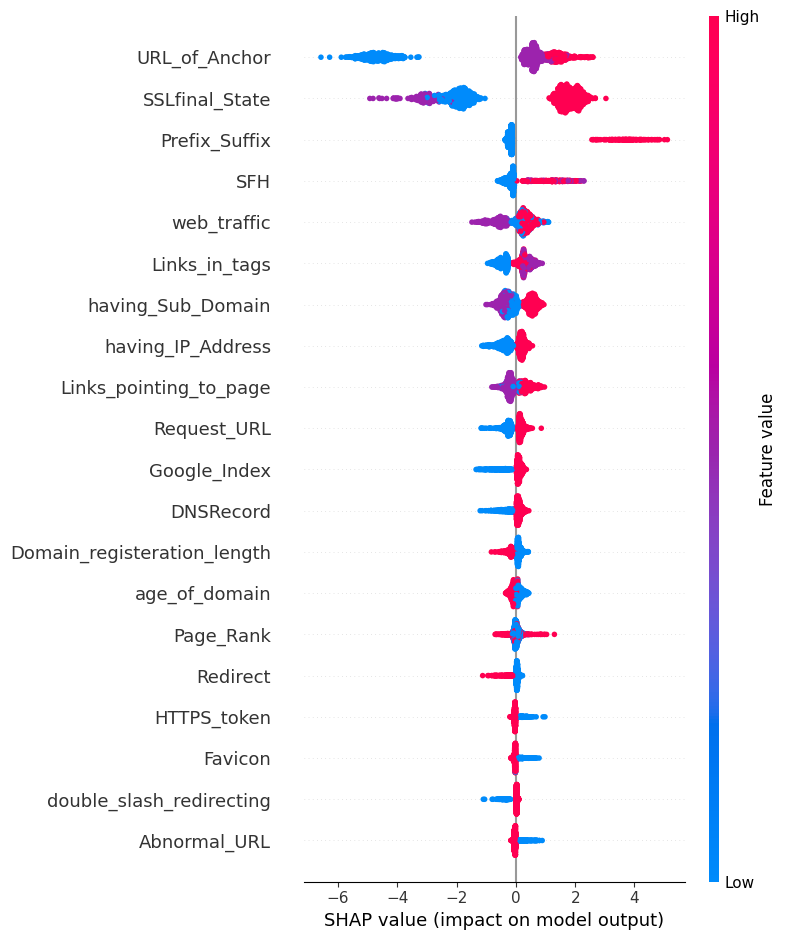

In [237]:
shap.summary_plot(
    shap_values,
    X_test
)

In [238]:
shape_position = X_test.index.get_loc(333)

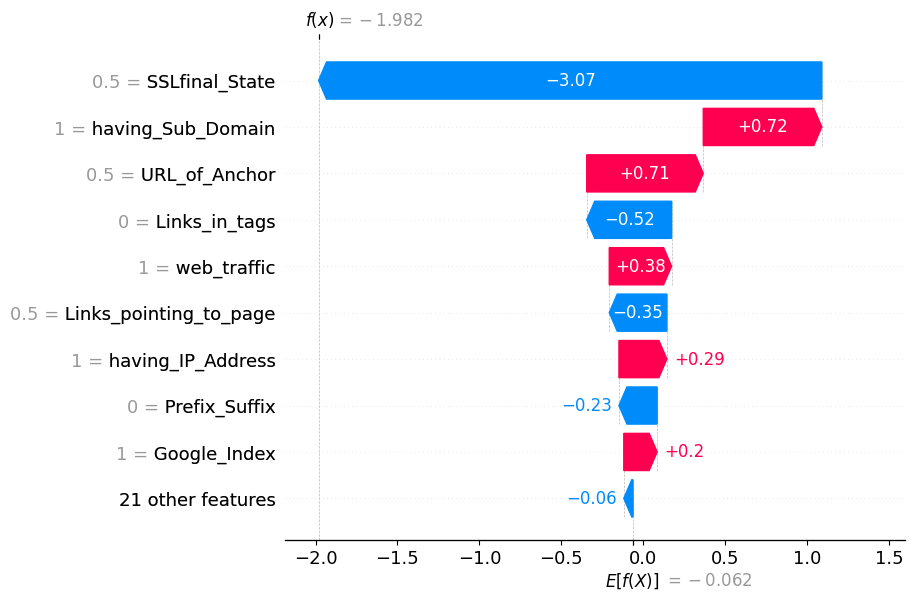

In [239]:
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[shape_position],
        base_values=explainer.expected_value,
        data=X_test.loc[333],
        feature_names=X_test.columns
    )
)

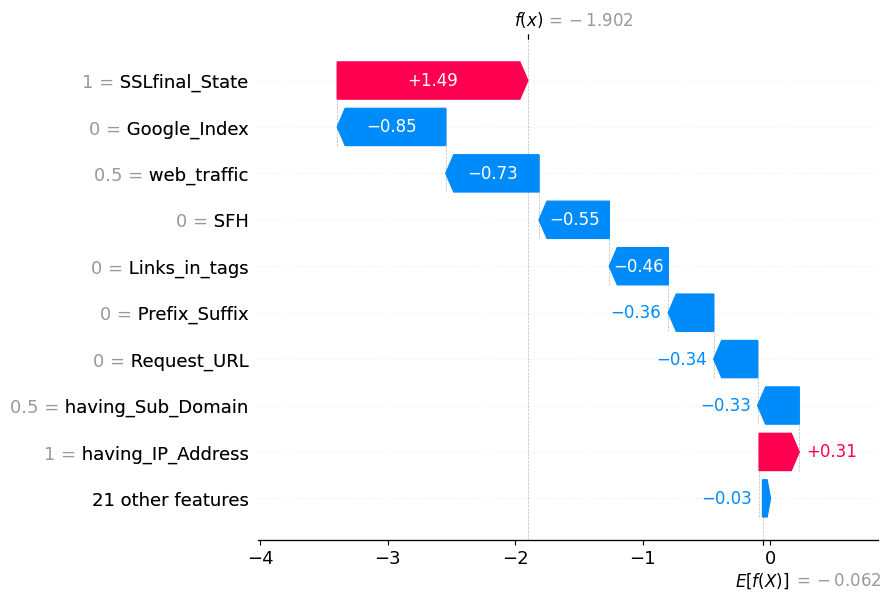

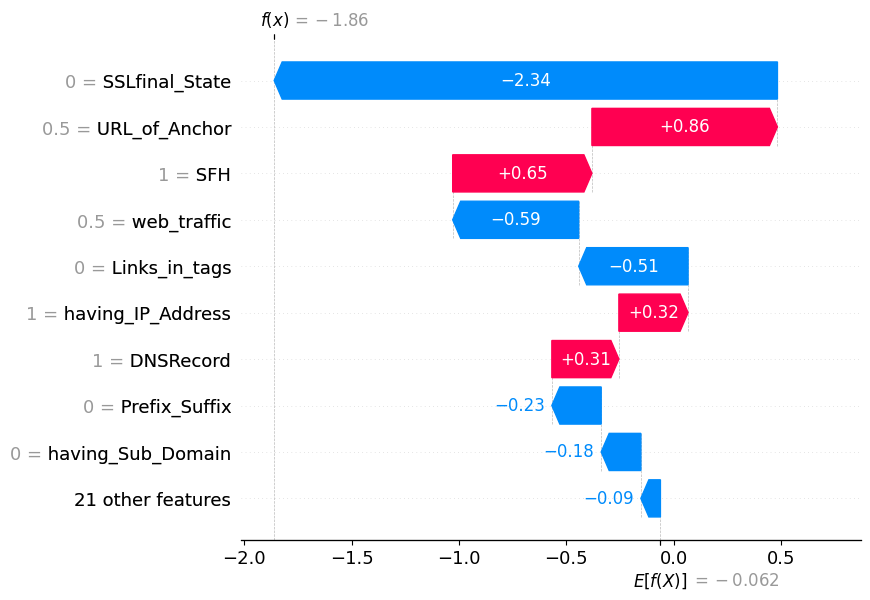

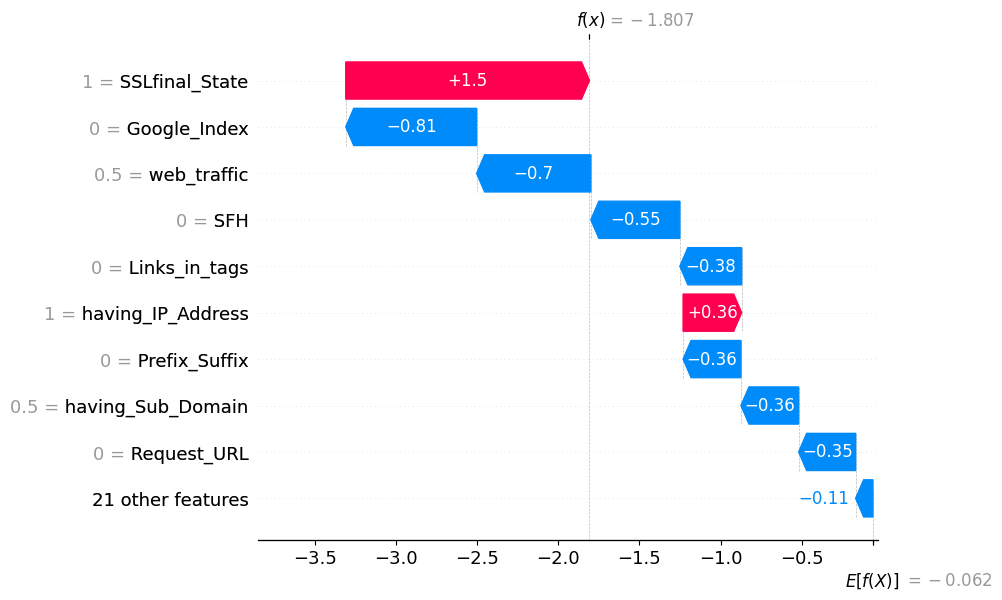

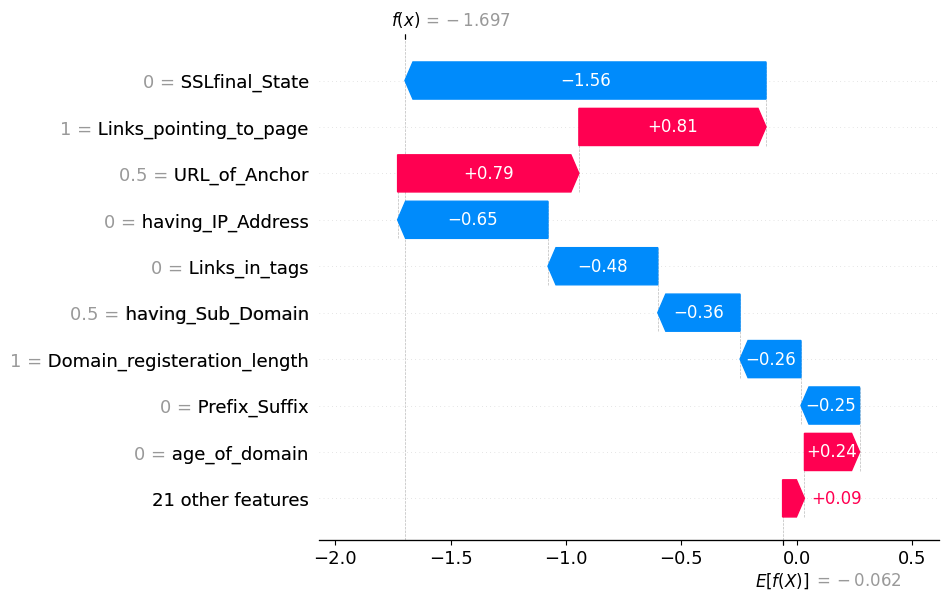

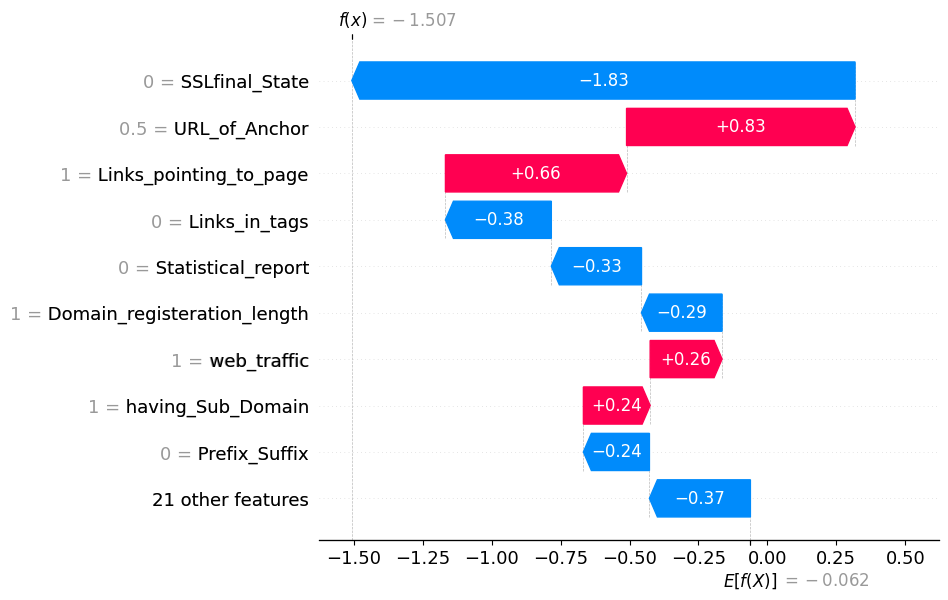

In [240]:
for url_id in [346, 4014, 4638, 2918, 1551]:
    idx = X_test.index.get_loc(url_id)

    shap.plots.waterfall(
        shap.Explanation(
            values=shap_values[idx],
            base_values=explainer.expected_value,
            data=X_test.loc[url_id],
            feature_names=X_test.columns
        )
    )

In [260]:
feature_contributions = pd.DataFrame({
    "Feature": X_test.columns,
    "SHAP_Value": shap_values[idx]
})

In [261]:
phishing_push = feature_contributions[
    feature_contributions["SHAP_Value"] > 0
].sort_values(
    by="SHAP_Value",
    ascending=False
)

print(phishing_push)

                     Feature  SHAP_Value
13             URL_of_Anchor    0.828772
28    Links_pointing_to_page    0.656890
25               web_traffic    0.260856
6          having_Sub_Domain    0.242152
27              Google_Index    0.222104
0          having_IP_Address    0.178624
16       Submitting_to_email    0.052957
18                  Redirect    0.047844
1                 URL_Length    0.031989
4   double_slash_redirecting    0.023191
22                    Iframe    0.019565
20                RightClick    0.008840


In [262]:
legitimate_push = feature_contributions[
    feature_contributions["SHAP_Value"] < 0
].sort_values(
    by="SHAP_Value"
)

print(legitimate_push)

                        Feature  SHAP_Value
7                SSLfinal_State   -1.825233
14                Links_in_tags   -0.384037
29           Statistical_report   -0.327025
8   Domain_registeration_length   -0.292293
5                 Prefix_Suffix   -0.239492
24                    DNSRecord   -0.218069
12                  Request_URL   -0.198179
15                          SFH   -0.180570
23                age_of_domain   -0.083965
2            Shortining_Service   -0.063444
11                  HTTPS_token   -0.054694
26                    Page_Rank   -0.050839
17                 Abnormal_URL   -0.035686
21                  popUpWidnow   -0.027046
9                       Favicon   -0.016651
3              having_At_Symbol   -0.014762
19                 on_mouseover   -0.006745
10                         port   -0.000677


In [277]:
top_phising=phishing_push.head(5)



In [276]:


top_legitimate=legitimate_push.head(5)
top_legitimate

,Feature,SHAP_Value,Abs_SHAP
7,SSLfinal_State,-3.072450,3.072450
14,Links_in_tags,-0.518256,0.518256
28,Links_pointing_to_page,-0.351936,0.351936
5,Prefix_Suffix,-0.233310,0.233310
15,SFH,-0.158048,0.158048


In [264]:
phishing_push["SHAP_Value"].sum()

np.float32(2.5737834)

In [ ]:
legitimate_push["SHAP_Value"].sum()

np.float32(-4.6711645)

In [430]:
def explain_predictionn(index_label):
    
    # Convert dataset index label into SHAP position
    idx = X_test.index.get_loc(index_label)

    # Create SHAP contribution table
    feature_contributions = pd.DataFrame({
        "Feature": X_test.columns,
        "SHAP_Value": shap_values[idx]
    })

    # Absolute SHAP values
    feature_contributions["Abs_SHAP"] = (
        feature_contributions["SHAP_Value"].abs()
    )

    # Features pushing toward phishing
    phishing_push = (
        feature_contributions[
            feature_contributions["SHAP_Value"] > 0
        ]
        .sort_values(by="SHAP_Value", ascending=False)
    )

    # Features pushing toward legitimate
    legitimate_push = (
        feature_contributions[
            feature_contributions["SHAP_Value"] < 0
        ]
        .sort_values(by="SHAP_Value")
    )

    # Total influence
    phishing_total = phishing_push["SHAP_Value"].sum()
    legitimate_total = legitimate_push["SHAP_Value"].sum()

    print("=" * 50)
    print(f"URL Index: {index_label}")
    print("=" * 50)

    print("\nTop Features Pushing Toward Phishing")
    print(phishing_push[["Feature", "SHAP_Value"]].head(5))

    print("\nTop Features Pushing Toward Legitimate")
    print(legitimate_push[["Feature", "SHAP_Value"]].head(5))

    print("\nTotal Phishing Push:", phishing_total)
    print("Total Legitimate Push:", legitimate_total)

    print("\nConclusion:")

    if abs(legitimate_total) > phishing_total:
        print(
            "Legitimate-oriented features had stronger "
            "overall influence than phishing-oriented features."
        )
    else:
        print(
            "Phishing-oriented features had stronger "
            "overall influence than legitimate-oriented features."
        )

    return (
        phishing_push,
        legitimate_push,
        phishing_total,
        legitimate_total
    )

In [431]:
print(phishing_total)
print(legitimate_total)

2.7510982
-4.6711645


In [432]:
explain_predictionn(2918)

URL Index: 2918

Top Features Pushing Toward Phishing
                   Feature  SHAP_Value
28  Links_pointing_to_page    0.810556
13           URL_of_Anchor    0.785156
23           age_of_domain    0.238907
27            Google_Index    0.222663
25             web_traffic    0.195932

Top Features Pushing Toward Legitimate
                        Feature  SHAP_Value
7                SSLfinal_State   -1.563870
0             having_IP_Address   -0.651338
14                Links_in_tags   -0.475582
6             having_Sub_Domain   -0.356275
8   Domain_registeration_length   -0.263869

Total Phishing Push: 2.570846
Total Legitimate Push: -4.2064457

Conclusion:
Legitimate-oriented features had stronger overall influence than phishing-oriented features.


(                     Feature  SHAP_Value  Abs_SHAP
 28    Links_pointing_to_page    0.810556  0.810556
 13             URL_of_Anchor    0.785156  0.785156
 23             age_of_domain    0.238907  0.238907
 27              Google_Index    0.222663  0.222663
 25               web_traffic    0.195932  0.195932
 26                 Page_Rank    0.080198  0.080198
 16       Submitting_to_email    0.060887  0.060887
 18                  Redirect    0.035532  0.035532
 1                 URL_Length    0.035026  0.035026
 29        Statistical_report    0.028285  0.028285
 24                 DNSRecord    0.027404  0.027404
 4   double_slash_redirecting    0.026265  0.026265
 22                    Iframe    0.015003  0.015003
 20                RightClick    0.009032  0.009032,
                         Feature  SHAP_Value  Abs_SHAP
 7                SSLfinal_State   -1.563870  1.563870
 0             having_IP_Address   -0.651338  0.651338
 14                Links_in_tags   -0.475582  0.475582

In [433]:
explain_predictionn(333)

URL Index: 333

Top Features Pushing Toward Phishing
              Feature  SHAP_Value
6   having_Sub_Domain    0.723712
13      URL_of_Anchor    0.711621
25        web_traffic    0.380611
0   having_IP_Address    0.292790
27       Google_Index    0.203772

Top Features Pushing Toward Legitimate
                   Feature  SHAP_Value
7           SSLfinal_State   -3.072450
14           Links_in_tags   -0.518256
28  Links_pointing_to_page   -0.351936
5            Prefix_Suffix   -0.233310
15                     SFH   -0.158048

Total Phishing Push: 2.7510982
Total Legitimate Push: -4.6711645

Conclusion:
Legitimate-oriented features had stronger overall influence than phishing-oriented features.


(                        Feature  SHAP_Value  Abs_SHAP
 6             having_Sub_Domain    0.723712  0.723712
 13                URL_of_Anchor    0.711621  0.711621
 25                  web_traffic    0.380611  0.380611
 0             having_IP_Address    0.292790  0.292790
 27                 Google_Index    0.203772  0.203772
 12                  Request_URL    0.132937  0.132937
 24                    DNSRecord    0.093557  0.093557
 8   Domain_registeration_length    0.091890  0.091890
 18                     Redirect    0.049741  0.049741
 29           Statistical_report    0.037641  0.037641
 4      double_slash_redirecting    0.015932  0.015932
 3              having_At_Symbol    0.010917  0.010917
 16          Submitting_to_email    0.003299  0.003299
 20                   RightClick    0.002679  0.002679,
                    Feature  SHAP_Value  Abs_SHAP
 7           SSLfinal_State   -3.072450  3.072450
 14           Links_in_tags   -0.518256  0.518256
 28  Links_pointing_to_p

In [434]:
explain_predictionn(4014)

URL Index: 4014

Top Features Pushing Toward Phishing
              Feature  SHAP_Value
13      URL_of_Anchor    0.863980
15                SFH    0.648319
0   having_IP_Address    0.322260
24          DNSRecord    0.312139
27       Google_Index    0.156782

Top Features Pushing Toward Legitimate
              Feature  SHAP_Value
7      SSLfinal_State   -2.343620
25        web_traffic   -0.586825
14      Links_in_tags   -0.509325
5       Prefix_Suffix   -0.229816
6   having_Sub_Domain   -0.184771

Total Phishing Push: 2.6966908
Total Legitimate Push: -4.495339

Conclusion:
Legitimate-oriented features had stronger overall influence than phishing-oriented features.


(                     Feature  SHAP_Value  Abs_SHAP
 13             URL_of_Anchor    0.863980  0.863980
 15                       SFH    0.648319  0.648319
 0          having_IP_Address    0.322260  0.322260
 24                 DNSRecord    0.312139  0.312139
 27              Google_Index    0.156782  0.156782
 26                 Page_Rank    0.130262  0.130262
 12               Request_URL    0.108847  0.108847
 18                  Redirect    0.055671  0.055671
 29        Statistical_report    0.048357  0.048357
 16       Submitting_to_email    0.017188  0.017188
 4   double_slash_redirecting    0.015560  0.015560
 3           having_At_Symbol    0.008792  0.008792
 20                RightClick    0.008533  0.008533,
                         Feature  SHAP_Value  Abs_SHAP
 7                SSLfinal_State   -2.343620  2.343620
 25                  web_traffic   -0.586825  0.586825
 14                Links_in_tags   -0.509325  0.509325
 5                 Prefix_Suffix   -0.229816  0.229

In [435]:
explain_predictionn(4638)

URL Index: 4638

Top Features Pushing Toward Phishing
                        Feature  SHAP_Value
7                SSLfinal_State    1.501017
0             having_IP_Address    0.360708
13                URL_of_Anchor    0.254132
24                    DNSRecord    0.189631
8   Domain_registeration_length    0.109202

Top Features Pushing Toward Legitimate
          Feature  SHAP_Value
27   Google_Index   -0.806056
25    web_traffic   -0.703374
15            SFH   -0.548141
14  Links_in_tags   -0.380623
5   Prefix_Suffix   -0.356389

Total Phishing Push: 2.5528073
Total Legitimate Push: -4.2984095

Conclusion:
Legitimate-oriented features had stronger overall influence than phishing-oriented features.


(                        Feature  SHAP_Value  Abs_SHAP
 7                SSLfinal_State    1.501017  1.501017
 0             having_IP_Address    0.360708  0.360708
 13                URL_of_Anchor    0.254132  0.254132
 24                    DNSRecord    0.189631  0.189631
 8   Domain_registeration_length    0.109202  0.109202
 4      double_slash_redirecting    0.037718  0.037718
 18                     Redirect    0.037282  0.037282
 22                       Iframe    0.022570  0.022570
 3              having_At_Symbol    0.021198  0.021198
 29           Statistical_report    0.017743  0.017743
 20                   RightClick    0.001606  0.001606,
                    Feature  SHAP_Value  Abs_SHAP
 27            Google_Index   -0.806056  0.806056
 25             web_traffic   -0.703374  0.703374
 15                     SFH   -0.548141  0.548141
 14           Links_in_tags   -0.380623  0.380623
 5            Prefix_Suffix   -0.356389  0.356389
 6        having_Sub_Domain   -0.355189

In [436]:
explain_predictionn(2918)

URL Index: 2918

Top Features Pushing Toward Phishing
                   Feature  SHAP_Value
28  Links_pointing_to_page    0.810556
13           URL_of_Anchor    0.785156
23           age_of_domain    0.238907
27            Google_Index    0.222663
25             web_traffic    0.195932

Top Features Pushing Toward Legitimate
                        Feature  SHAP_Value
7                SSLfinal_State   -1.563870
0             having_IP_Address   -0.651338
14                Links_in_tags   -0.475582
6             having_Sub_Domain   -0.356275
8   Domain_registeration_length   -0.263869

Total Phishing Push: 2.570846
Total Legitimate Push: -4.2064457

Conclusion:
Legitimate-oriented features had stronger overall influence than phishing-oriented features.


(                     Feature  SHAP_Value  Abs_SHAP
 28    Links_pointing_to_page    0.810556  0.810556
 13             URL_of_Anchor    0.785156  0.785156
 23             age_of_domain    0.238907  0.238907
 27              Google_Index    0.222663  0.222663
 25               web_traffic    0.195932  0.195932
 26                 Page_Rank    0.080198  0.080198
 16       Submitting_to_email    0.060887  0.060887
 18                  Redirect    0.035532  0.035532
 1                 URL_Length    0.035026  0.035026
 29        Statistical_report    0.028285  0.028285
 24                 DNSRecord    0.027404  0.027404
 4   double_slash_redirecting    0.026265  0.026265
 22                    Iframe    0.015003  0.015003
 20                RightClick    0.009032  0.009032,
                         Feature  SHAP_Value  Abs_SHAP
 7                SSLfinal_State   -1.563870  1.563870
 0             having_IP_Address   -0.651338  0.651338
 14                Links_in_tags   -0.475582  0.475582

In [444]:
def explain_prediction(index_label):
    
    # Convert dataset index label into SHAP position
    idx = X_test.index.get_loc(index_label)

    # Create SHAP contribution table
    feature_contributions = pd.DataFrame({
        "Feature": X_test.columns,
        "SHAP_Value": shap_values[idx]
    })

    # Absolute SHAP values
    feature_contributions["Abs_SHAP"] = (
        feature_contributions["SHAP_Value"].abs()
    )

    # Features pushing toward phishing
    phishing_push = (
        feature_contributions[
            feature_contributions["SHAP_Value"] > 0
        ]
        .sort_values(by="SHAP_Value", ascending=False)
    )

    # Features pushing toward legitimate
    legitimate_push = (
        feature_contributions[
            feature_contributions["SHAP_Value"] < 0
        ]
        .sort_values(by="SHAP_Value")
    )

    # Total influence
    phishing_total = phishing_push["SHAP_Value"].sum()
    legitimate_total = legitimate_push["SHAP_Value"].sum()

    return (
        phishing_push,
        legitimate_push,
        phishing_total,
        legitimate_total
    )

In [449]:
phishing_push, legitimate_push, phishing_total, legitimate_total = explain_prediction(346)

In [450]:
print("Phishing total:", phishing_total)
print("Legitimate total:", legitimate_total)
print("Absolute legitimate total:", abs(legitimate_total))

Phishing total: 2.5617487
Legitimate total: -4.4018164
Absolute legitimate total: 4.4018164


In [369]:
feature_descriptions = {

    "having_IP_Address": {
        "positive": "Using an IP address instead of a normal domain increased phishing suspicion.",
        "negative": "The website address format appeared normal and reduced phishing suspicion."
    },

    "URL_Length": {
        "positive": "The unusually long web address increased phishing suspicion.",
        "negative": "The web address length appeared normal and supported legitimacy."
    },

    "Prefix_Suffix": {
        "positive": "The website address structure looked suspicious and increased phishing suspicion.",
        "negative": "The website address structure appeared normal and supported legitimacy."
    },

    "having_Sub_Domain": {
        "positive": "The large number of subdomains increased phishing suspicion.",
        "negative": "The subdomain structure appeared normal and supported legitimacy."
    },

    "SSLfinal_State": {
        "positive": "Website security indicators increased phishing suspicion.",
        "negative": "Website security indicators suggested that the site appeared trustworthy."
    },

    "Domain_registeration_length": {
        "positive": "The domain registration characteristics increased phishing suspicion.",
        "negative": "The domain registration characteristics appeared consistent with legitimate websites."
    },

    "Request_URL": {
        "positive": "The way webpage resources were requested increased phishing suspicion.",
        "negative": "The resource request patterns appeared normal and supported legitimacy."
    },

    "URL_of_Anchor": {
        "positive": "The website's links showed patterns commonly seen in phishing websites.",
        "negative": "The website's links appeared consistent with legitimate websites."
    },

    "Links_in_tags": {
        "positive": "The structure of webpage links increased phishing suspicion.",
        "negative": "The structure of webpage links resembled legitimate websites."
    },

    "SFH": {
        "positive": "The way forms handled user information increased phishing suspicion.",
        "negative": "The way forms handled user information appeared trustworthy."
    },

    "Redirect": {
        "positive": "The website's redirection behavior increased phishing suspicion.",
        "negative": "The website's redirection behavior appeared normal."
    },

    "age_of_domain": {
        "positive": "The domain age increased phishing suspicion.",
        "negative": "The domain age supported website legitimacy."
    },

    "DNSRecord": {
        "positive": "The domain registration information increased phishing suspicion.",
        "negative": "The domain registration information appeared trustworthy."
    },

    "web_traffic": {
        "positive": "The website traffic pattern increased phishing suspicion.",
        "negative": "The website traffic pattern resembled legitimate websites."
    },

    "Page_Rank": {
        "positive": "The website's online reputation increased phishing suspicion.",
        "negative": "The website's online reputation supported legitimacy."
    },

    "Google_Index": {
        "positive": "Search engine indexing characteristics increased phishing suspicion.",
        "negative": "The website appeared similar to indexed and established websites."
    },

    "Links_pointing_to_page": {
        "positive": "The pattern of external links increased phishing suspicion.",
        "negative": "The pattern of external links appeared consistent with legitimate websites."
    },

    "Statistical_report": {
        "positive": "Historical phishing-related indicators increased phishing suspicion.",
        "negative": "Historical indicators appeared consistent with legitimate websites."
    }
}

In [370]:
legitimate_reasons = []
for _, row in top_legitimate.iterrows():

    feature = row["Feature"]
    reason = (
        feature_descriptions
        .get(feature, {})
        .get("negative", feature)
    )
   
    legitimate_reasons.append(reason)

In [371]:
phishing_reasons = []
for _, row in top_phising.iterrows():

    feature = row["Feature"]

    reason = (
        feature_descriptions
        .get(feature, {})
        .get("positive", feature)
    )

    phishing_reasons.append(reason)
    

In [372]:
print(phishing_reasons)
print(legitimate_reasons)

['The large number of subdomains increased phishing suspicion.', "The website's links showed patterns commonly seen in phishing websites.", 'The website traffic pattern increased phishing suspicion.', 'Using an IP address instead of a normal domain increased phishing suspicion.', 'Search engine indexing characteristics increased phishing suspicion.']
['Website security indicators suggested that the site appeared trustworthy.', 'The structure of webpage links resembled legitimate websites.', 'The pattern of external links appeared consistent with legitimate websites.', 'The website address structure appeared normal and supported legitimacy.', 'The way forms handled user information appeared trustworthy.']


In [373]:
if abs(legitimate_total) > phishing_total:

    final_explanation = (
        f"Although several phishing indicators were detected, "
        f"the legitimate-oriented features exerted a stronger "
        f"overall influence ({abs(legitimate_total):.2f}) "
        f"than the phishing-oriented features "
        f"({phishing_total:.2f})."
    )

else:

    final_explanation = (
        f"The phishing-oriented features exerted a stronger "
        f"overall influence ({phishing_total:.2f}) than the "
        f"legitimate-oriented features "
        f"({abs(legitimate_total):.2f})."
    )

In [374]:
url_position=X_test.index.get_loc(333)
prediction=y_pred[url_position]
print(prediction)

1


In [375]:
if prediction == 1:
    prediction_label = "Phishing"
else:
    prediction_label = "Legitimate"

In [376]:
print("Factors increasing phishing suspicion:")

for reason in phishing_reasons:
    print("•", reason)

print("\nFactors supporting legitimacy:")

for reason in legitimate_reasons:
    print("•", reason)

print(f"\nFinal Prediction: {prediction_label}")

print("\nConclusion:")
print(final_explanation)

Factors increasing phishing suspicion:
• The large number of subdomains increased phishing suspicion.
• The website's links showed patterns commonly seen in phishing websites.
• The website traffic pattern increased phishing suspicion.
• Using an IP address instead of a normal domain increased phishing suspicion.
• Search engine indexing characteristics increased phishing suspicion.

Factors supporting legitimacy:
• Website security indicators suggested that the site appeared trustworthy.
• The structure of webpage links resembled legitimate websites.
• The pattern of external links appeared consistent with legitimate websites.
• The website address structure appeared normal and supported legitimacy.
• The way forms handled user information appeared trustworthy.

Final Prediction: Phishing

Conclusion:
Although several phishing indicators were detected, the legitimate-oriented features exerted a stronger overall influence (4.67) than the phishing-oriented features (2.75).


In [377]:
explain_prediction(333)

URL Index: 333

Top Features Pushing Toward Phishing
              Feature  SHAP_Value
6   having_Sub_Domain    0.723712
13      URL_of_Anchor    0.711621
25        web_traffic    0.380611
0   having_IP_Address    0.292790
27       Google_Index    0.203772

Top Features Pushing Toward Legitimate
                   Feature  SHAP_Value
7           SSLfinal_State   -3.072450
14           Links_in_tags   -0.518256
28  Links_pointing_to_page   -0.351936
5            Prefix_Suffix   -0.233310
15                     SFH   -0.158048

Total Phishing Push: 2.7510982
Total Legitimate Push: -4.6711645

Conclusion:
Legitimate-oriented features had stronger overall influence than phishing-oriented features.


(                        Feature  SHAP_Value  Abs_SHAP
 6             having_Sub_Domain    0.723712  0.723712
 13                URL_of_Anchor    0.711621  0.711621
 25                  web_traffic    0.380611  0.380611
 0             having_IP_Address    0.292790  0.292790
 27                 Google_Index    0.203772  0.203772
 12                  Request_URL    0.132937  0.132937
 24                    DNSRecord    0.093557  0.093557
 8   Domain_registeration_length    0.091890  0.091890
 18                     Redirect    0.049741  0.049741
 29           Statistical_report    0.037641  0.037641
 4      double_slash_redirecting    0.015932  0.015932
 3              having_At_Symbol    0.010917  0.010917
 16          Submitting_to_email    0.003299  0.003299
 20                   RightClick    0.002679  0.002679,
                    Feature  SHAP_Value  Abs_SHAP
 7           SSLfinal_State   -3.072450  3.072450
 14           Links_in_tags   -0.518256  0.518256
 28  Links_pointing_to_p

In [445]:
def generate_explanation(index_label):

    phishing_push, legitimate_push, phishing_total, legitimate_total = (
        explain_prediction(index_label)
    )

    top_legitimate = legitimate_push.head(5)
    top_phishing = phishing_push.head(5)

    legitimate_reasons = []

    for _, row in top_legitimate.iterrows():

        feature = row["Feature"]

        reason = (
            feature_descriptions
            .get(feature, {})
            .get("negative", feature)
        )

        legitimate_reasons.append(reason)

    phishing_reasons = []

    for _, row in top_phishing.iterrows():

        feature = row["Feature"]

        reason = (
            feature_descriptions
            .get(feature, {})
            .get("positive", feature)
        )

        phishing_reasons.append(reason)

    if abs(legitimate_total) > phishing_total:

        final_explanation = (
            f"Although several phishing indicators were detected, "
            f"the legitimate-oriented features exerted a stronger "
            f"overall influence ({abs(legitimate_total):.2f}) "
            f"than the phishing-oriented features "
            f"({phishing_total:.2f})."
        )

    else:

        final_explanation = (
            f"The phishing-oriented features exerted a stronger "
            f"overall influence ({phishing_total:.2f}) than the "
            f"legitimate-oriented features "
            f"({abs(legitimate_total):.2f})."
        )

   
    url_position = X_test.index.get_loc(index_label)

    prediction = y_pred[url_position]

    if prediction == 1:
        prediction_label = "Phishing"
    else:
        prediction_label = "Legitimate"

   
    print("\nFactors increasing phishing suspicion:")

    for reason in phishing_reasons:
        print("•", reason)

    print("\nFactors supporting legitimacy:")

    for reason in legitimate_reasons:
        print("•", reason)

    print(f"\nFinal Prediction: {prediction_label}")

    print("\nConclusion:")
    print(final_explanation)

In [441]:
generate_explanation(333)


Factors increasing phishing suspicion:
• The large number of subdomains increased phishing suspicion.
• The website's links showed patterns commonly seen in phishing websites.
• The website traffic pattern increased phishing suspicion.
• Using an IP address instead of a normal domain increased phishing suspicion.
• Search engine indexing characteristics increased phishing suspicion.

Factors supporting legitimacy:
• Website security indicators suggested that the site appeared trustworthy.
• The structure of webpage links resembled legitimate websites.
• The pattern of external links appeared consistent with legitimate websites.
• The website address structure appeared normal and supported legitimacy.
• The way forms handled user information appeared trustworthy.

Final Prediction: Phishing

Conclusion:
Although several phishing indicators were detected, the legitimate-oriented features exerted a stronger overall influence (4.67) than the phishing-oriented features (2.75).


In [442]:
generate_explanation(2918)


Factors increasing phishing suspicion:
• The pattern of external links increased phishing suspicion.
• The website's links showed patterns commonly seen in phishing websites.
• The domain age increased phishing suspicion.
• Search engine indexing characteristics increased phishing suspicion.
• The website traffic pattern increased phishing suspicion.

Factors supporting legitimacy:
• Website security indicators suggested that the site appeared trustworthy.
• The website address format appeared normal and reduced phishing suspicion.
• The structure of webpage links resembled legitimate websites.
• The subdomain structure appeared normal and supported legitimacy.
• The domain registration characteristics appeared consistent with legitimate websites.

Final Prediction: Legitimate

Conclusion:
Although several phishing indicators were detected, the legitimate-oriented features exerted a stronger overall influence (4.21) than the phishing-oriented features (2.57).


In [451]:
generate_explanation(2918)


Factors increasing phishing suspicion:
• The pattern of external links increased phishing suspicion.
• The website's links showed patterns commonly seen in phishing websites.
• The domain age increased phishing suspicion.
• Search engine indexing characteristics increased phishing suspicion.
• The website traffic pattern increased phishing suspicion.

Factors supporting legitimacy:
• Website security indicators suggested that the site appeared trustworthy.
• The website address format appeared normal and reduced phishing suspicion.
• The structure of webpage links resembled legitimate websites.
• The subdomain structure appeared normal and supported legitimacy.
• The domain registration characteristics appeared consistent with legitimate websites.

Final Prediction: Legitimate

Conclusion:
Although several phishing indicators were detected, the legitimate-oriented features exerted a stronger overall influence (4.21) than the phishing-oriented features (2.57).
